# Pairs Trading: Cointegration, Kalman Hedge Ratios, and an Honest Backtest

Two stocks driven by the same fundamentals (two banks, two oil majors) can drift apart for a
while but tend to come back together. When
$\log A_t - \beta \log B_t - \alpha$ is **stationary**, the pair is *cointegrated* and the
spread can be traded: sell it when it is unusually wide, buy it when it is unusually narrow.

This notebook follows the workflow of a stat-arb desk:
1. **Formation period** (two years): Engle-Granger test, hedge ratio, half-life of the spread.
2. **Hedge ratio over time:** a Kalman filter lets $\beta$ drift, against a static OLS hedge.
3. **Trading period** (eight years, out of sample): z-score bands, one-day execution lag, 5 bp costs.
4. **Robustness:** 10 simulated pairs × 3 levels of beta drift, then pairs that are *not* cointegrated.

The data are simulated so that the true hedge ratio is known and every estimate can be checked.

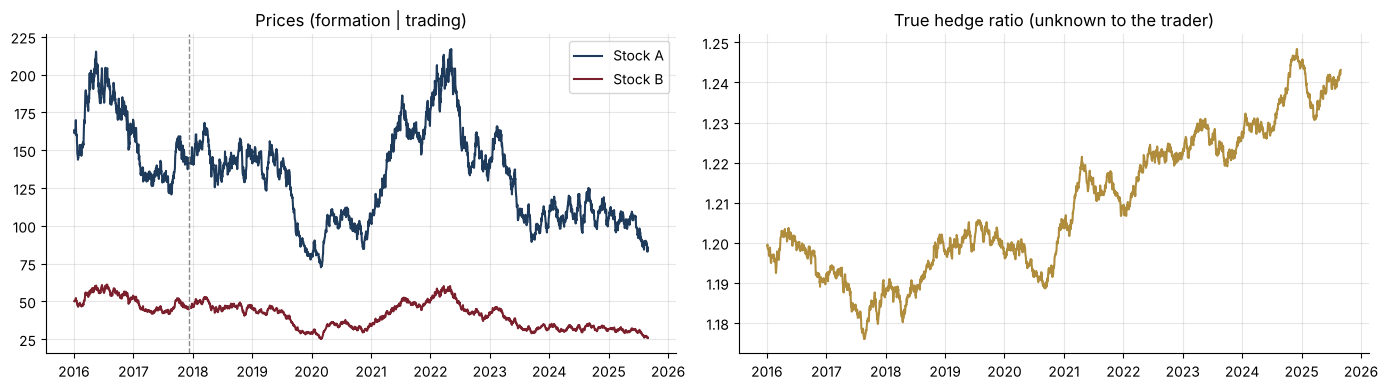

In [1]:
import os, sys, subprocess
if "google.colab" in sys.modules and not os.path.exists("pairs.py"):
    subprocess.run(["git", "clone", "-q", "https://github.com/adamrejeb86-del/-finance-portfolio.git"], check=True)
    os.chdir("-finance-portfolio/30-pairs-trading-kalman")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pairs import (EG_CRITICAL_5PCT, simulate_pair, engle_granger, half_life, kalman_hedge, rolling_z,
                   backtest_spread, stats)

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
NAVY, BORDEAUX, GREY, TEAL, GOLD = "#1f3b5c", "#7a1f2b", "#8a8a8a", "#2a7f7f", "#b08d3c"
FORM = 504                       # two-year formation period, then trade out of sample

prices, true_beta = simulate_pair(seed=0, beta_drift=0.0007)
logA, logB = np.log(prices["A"]), np.log(prices["B"])
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(prices["A"], color=NAVY, label="Stock A"); axes[0].plot(prices["B"], color=BORDEAUX, label="Stock B")
axes[0].axvline(prices.index[FORM], color=GREY, ls="--", lw=1); axes[0].set_title("Prices (formation | trading)"); axes[0].legend()
axes[1].plot(true_beta, color=GOLD); axes[1].set_title("True hedge ratio (unknown to the trader)")
plt.tight_layout(); plt.savefig("images/prices.png", dpi=150); plt.show()

## 1. Formation period: is the pair cointegrated?

Engle-Granger in two steps: regress $\log A$ on $\log B$ by OLS, then run an augmented
Dickey-Fuller test on the residuals. The critical value is more negative than for a plain ADF
test ($-3.34$ instead of $-2.86$) because the hedge ratio was estimated to make the residuals look
as stationary as possible. As a control, the same test is run on a pair built **without**
cointegration.

In [2]:
eg = engle_granger(logA[:FORM], logB[:FORM])
fake, _ = simulate_pair(seed=0, beta_drift=0.0007, cointegrated=False)
eg_fake = engle_granger(np.log(fake["A"])[:FORM], np.log(fake["B"])[:FORM])
pd.DataFrame({"Cointegrated pair": [eg["beta"], eg["adf_stat"], EG_CRITICAL_5PCT, eg["cointegrated_5pct"], half_life(eg["residuals"])],
              "Unrelated pair": [eg_fake["beta"], eg_fake["adf_stat"], EG_CRITICAL_5PCT, eg_fake["cointegrated_5pct"], half_life(eg_fake["residuals"])]},
             index=["OLS hedge ratio", "ADF statistic", "5% critical value", "Cointegrated?", "Half-life (days)"]).round(2)

,Cointegrated pair,Unrelated pair
OLS hedge ratio,1.378069,1.885689
ADF statistic,-3.571401,-3.207948
5% critical value,-3.34,-3.34
Cointegrated?,True,False
Half-life (days),14.380599,18.742038


The real pair passes and its spread has a half-life of about two to three weeks (the simulation
uses 15 days), which is short enough to trade. The unrelated pair fails, but only just, and its
estimated half-life looks just as tradeable: over two years a random walk can imitate mean
reversion. Reading the half-life alone would have accepted it.

## 2. The hedge ratio over time: static OLS vs Kalman filter

The static hedge freezes $\beta$ at its formation-period estimate. The Kalman filter treats
$\beta_t$ as a random walk and updates it every day from the new prices:

$$\log A_t = \beta_t \log B_t + \alpha + \varepsilon_t, \qquad \beta_t = \beta_{t-1} + w_t.$$

The intercept is kept almost fixed on purpose: when I let it move freely, it absorbed the spread
itself and the strategy never traded.

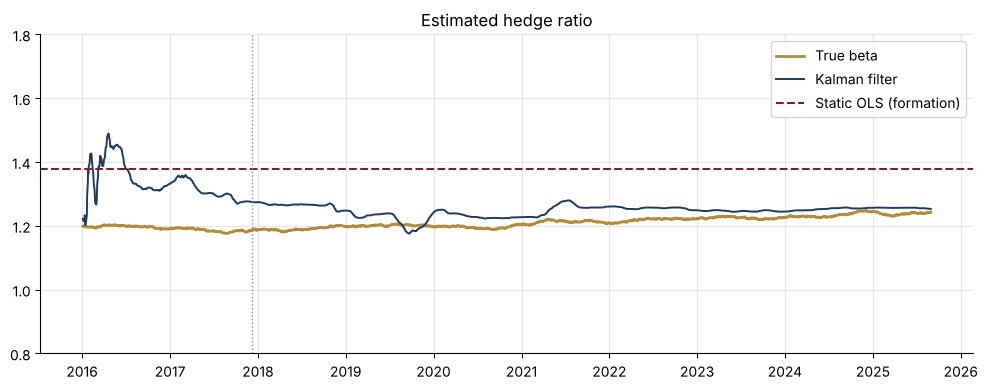

Mean absolute error on beta, trading period: static 0.165, Kalman 0.035


In [3]:
kal = kalman_hedge(logA, logB, delta_beta=1e-8)
static_spread = (logA - eg["beta"] * logB - eg["alpha"]).values
plt.figure(figsize=(10, 4))
plt.plot(true_beta, color=GOLD, lw=2, label="True beta")
plt.plot(prices.index, kal["beta"], color=NAVY, lw=1.4, label="Kalman filter")
plt.axhline(eg["beta"], color=BORDEAUX, ls="--", label="Static OLS (formation)")
plt.axvline(prices.index[FORM], color=GREY, ls=":", lw=1)
plt.ylim(0.8, 1.8); plt.legend(); plt.title("Estimated hedge ratio")
plt.tight_layout(); plt.savefig("images/hedge_ratio.png", dpi=150); plt.show()
trade = slice(FORM, None)
print(f"Mean absolute error on beta, trading period: static {np.abs(eg['beta'] - true_beta.values[trade]).mean():.3f}, "
      f"Kalman {np.abs(kal['beta'][trade] - true_beta.values[trade]).mean():.3f}")

The static estimate is wrong from the start (about 1.38 against a true value near 1.2): over two
years the spread and $\log B$ happen to move together, and OLS loads that onto the hedge ratio.
The filter keeps learning and ends close to the true beta. The obvious expectation is that the
Kalman version will trade better. Let's check.

## 3. Trading the spread out of sample

Three versions of the same rule (enter at $|z| > 2$, exit at $|z| < 0.5$, trade the next day,
5 bp per unit of turnover, gross exposure 1):

| Strategy | Hedge ratio | z-score |
|---|---|---|
| Textbook | static OLS | mean and std frozen at the formation period |
| Static + rolling z | static OLS | mean and std of the previous 60 days |
| Kalman | Kalman filter | one-step-ahead error, 60-day rolling z |

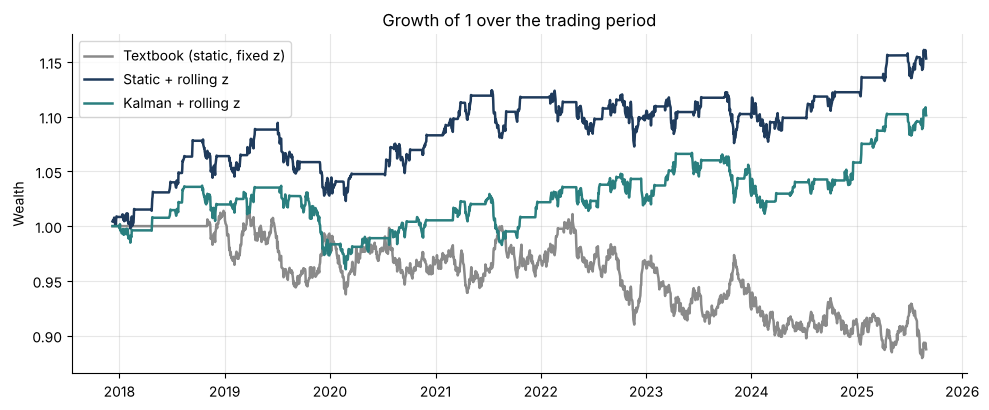

,Annual return,Volatility,Sharpe,Max drawdown,Trades,Days in a position
"Textbook (static, fixed z)",-0.01,0.06,-0.24,-0.13,3.0,0.88
Static + rolling z,0.02,0.04,0.48,-0.07,80.0,0.42
Kalman + rolling z,0.01,0.04,0.33,-0.07,87.0,0.43


In [4]:
z_fixed = (static_spread - static_spread[:FORM].mean()) / static_spread[:FORM].std()
runs = {"Textbook (static, fixed z)": backtest_spread(prices, np.full(len(prices), eg["beta"]), z_fixed),
        "Static + rolling z": backtest_spread(prices, np.full(len(prices), eg["beta"]), rolling_z(static_spread)),
        "Kalman + rolling z": backtest_spread(prices, kal["beta"], rolling_z(kal["spread"]))}
fig, ax = plt.subplots(figsize=(10, 4.2))
rows = {}
for (name, (r, pos)), c in zip(runs.items(), [GREY, NAVY, TEAL]):
    r = r[trade]
    ax.plot((1 + r).cumprod(), color=c, lw=1.8, label=name)
    rows[name] = {**stats(r), "Trades": int((np.diff(pos[trade]) != 0).sum()), "Days in a position": (pos[trade] != 0).mean()}
ax.set(title="Growth of 1 over the trading period", ylabel="Wealth"); ax.legend()
plt.tight_layout(); plt.savefig("images/equity.png", dpi=150); plt.show()
pd.DataFrame(rows).T.round(2)

The ranking is not the one I expected. Freezing the z-score is the real mistake: because the
static hedge ratio is off, part of every move in B leaks into the spread, which wanders away from
its formation-period mean, and the strategy sits in losing positions (88% of the days, 3 trades). A **rolling z-score** on the very same static spread fixes most of it. The
Kalman version is better than the textbook one but does **not** beat the simpler fix, even though
its hedge ratio is far more accurate.

One pair could be luck, so the next section repeats the test on many.

## 4. Robustness: 10 pairs × 3 levels of beta drift

In [5]:
def run_pair(seed, drift, cointegrated=True):
    p, _ = simulate_pair(seed=seed, beta_drift=drift, cointegrated=cointegrated)
    la, lb = np.log(p["A"]), np.log(p["B"])
    e = engle_granger(la[:FORM], lb[:FORM])
    sp = (la - e["beta"] * lb - e["alpha"]).values
    zf = (sp - sp[:FORM].mean()) / sp[:FORM].std()
    k = kalman_hedge(la, lb, delta_beta=1e-8)
    out = {"EG passes": e["cointegrated_5pct"]}
    for name, (h, z) in {"Textbook": (np.full(len(p), e["beta"]), zf), "Static + rolling z": (np.full(len(p), e["beta"]), rolling_z(sp)),
                         "Kalman + rolling z": (k["beta"], rolling_z(k["spread"]))}.items():
        out[name] = stats(backtest_spread(p, h, z)[0][trade])["Sharpe"]
    return out

grid = pd.DataFrame([{"Beta drift": d, **run_pair(s, d)} for d in (0.0005, 0.001, 0.002) for s in range(10)])
summary = grid.groupby("Beta drift").mean()
summary.columns = ["Share passing EG"] + [f"Sharpe: {c}" for c in summary.columns[1:]]
summary.round(2)

,Share passing EG,Sharpe: Textbook,Sharpe: Static + rolling z,Sharpe: Kalman + rolling z
Beta drift,,,,
0.0005,0.4,0.52,1.02,0.77
0.0010,0.3,0.18,0.82,0.63
0.0020,0.1,0.04,0.56,0.37


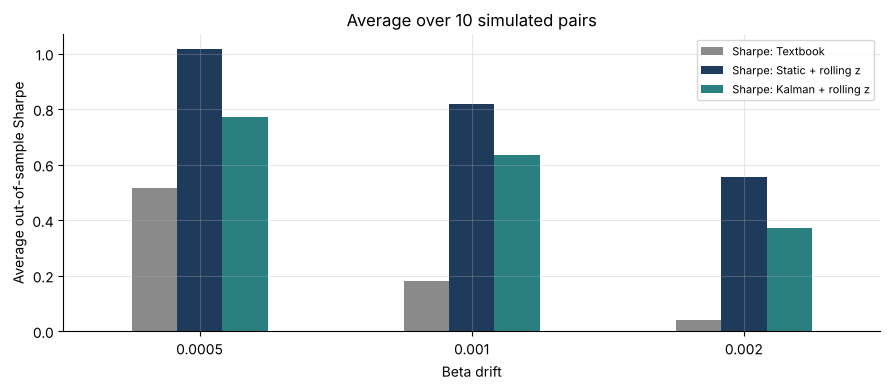

In [6]:
ax = summary.iloc[:, 1:].plot(kind="bar", color=[GREY, NAVY, TEAL], figsize=(9, 4), rot=0)
ax.set(ylabel="Average out-of-sample Sharpe", title="Average over 10 simulated pairs"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("images/robustness.png", dpi=150); plt.show()

Three results hold across the grid:

- **Static hedge + rolling z-score beats the Kalman version at every drift level**, so the first
  pair was not a fluke.
- **The textbook version collapses as the drift grows**: a frozen z-score is the real danger.
- **The Engle-Granger test misses many pairs that are truly cointegrated**: two years of data
  with a drifting hedge ratio give the test low power. A desk would combine it with economic
  reasoning (same sector, same drivers) instead of trading only the pairs that pass.

## 5. Where does the Kalman version lose: the hedge or the signal?

The Kalman filter plays two roles: it gives the **hedge ratio** used to size the legs, and its
one-step-ahead error is the **signal**. Swapping them one at a time separates the two effects.
The last line uses the true beta and the true spread, an upper bound no trader can reach.

In [7]:
def decompose(seed, drift=0.001):
    p, b = simulate_pair(seed=seed, beta_drift=drift)
    la, lb = np.log(p["A"]), np.log(p["B"])
    e = engle_granger(la[:FORM], lb[:FORM])
    h_static, sp = np.full(len(p), e["beta"]), (la - e["beta"] * lb - e["alpha"]).values
    k = kalman_hedge(la, lb, delta_beta=1e-8)
    combos = {"Static hedge, static-spread signal": (h_static, rolling_z(sp)),
              "Kalman hedge, static-spread signal": (k["beta"], rolling_z(sp)),
              "Static hedge, Kalman signal": (h_static, rolling_z(k["spread"])),
              "Kalman hedge, Kalman signal": (k["beta"], rolling_z(k["spread"])),
              "Oracle: true beta and true spread": (b.values, rolling_z((la - b * lb - 0.4).values))}
    return {name: stats(backtest_spread(p, h, z)[0][trade])["Sharpe"] for name, (h, z) in combos.items()}

pd.DataFrame([decompose(s) for s in range(10)]).mean().round(2).to_frame("Average Sharpe (10 pairs, drift 0.001)")

,"Average Sharpe (10 pairs, drift 0.001)"
"Static hedge, static-spread signal",0.82
"Kalman hedge, static-spread signal",0.85
"Static hedge, Kalman signal",0.62
"Kalman hedge, Kalman signal",0.63
Oracle: true beta and true spread,1.20


In [8]:
# Share of each day's error that the update moves into the fitted line (beta and alpha)
post = logA.values - kal["beta"] * logB.values - kal["alpha"]
absorbed = np.median(1 - post[FORM:] / kal["spread"][FORM:])
print(f"Each update absorbs about {absorbed:.1%} of that day's spread error.")
print(f"Over 15 days (the half-life) a persistent deviation is absorbed by about {1 - (1 - absorbed) ** 15:.0%}.")

Each update absorbs about 1.4% of that day's spread error.
Over 15 days (the half-life) a persistent deviation is absorbed by about 20%.


The Kalman **hedge ratio is fine**: used with the static-spread signal it does slightly better
than the static hedge. The loss comes from the **signal**. Every update moves the filter's fitted
line a little towards today's price, so a deviation that persists for a few weeks, which is
exactly the trade, is partly explained away as a change in beta before it is traded. When
$\log B$ moves little from day to day, a wider spread and a higher beta look almost the same.

The gap to the oracle shows how much is lost by not knowing the true relationship: about a third
of the Sharpe ratio.

## 6. What happens with pairs that are not cointegrated?

In [9]:
fake_runs = pd.DataFrame([run_pair(s, 0.0007, cointegrated=False) for s in range(10)])
print(f"Unrelated pairs that wrongly pass Engle-Granger: {fake_runs['EG passes'].sum()} / 10")
fake_runs.drop(columns="EG passes").mean().round(2).to_frame("Average Sharpe, unrelated pairs")

Unrelated pairs that wrongly pass Engle-Granger: 0 / 10


,"Average Sharpe, unrelated pairs"
Textbook,-0.14
Static + rolling z,-0.10
Kalman + rolling z,-0.19


Without a real economic link, all three versions lose money on average: they bet on mean
reversion in a spread that is a random walk. None of the ten unrelated pairs passes the test, so
here it does its job as a filter. Its cost is on the other side: the good pairs it rejects
(section 4).

## Conclusions
- Cointegration testing, half-life, Kalman filter and a backtest with no look-ahead and costs,
  all checked by unit tests (`test_pairs.py`).
- The Kalman filter estimates the hedge ratio much better than a static regression, yet a static
  hedge with a rolling z-score trades better on these simulations. The decomposition shows why:
  the Kalman hedge is good, the Kalman signal is not. Estimation accuracy and trading performance
  are two different objectives.
- **Next steps:** apply it to real sector pairs (with survivorship-free data), estimate the hedge
  ratio on returns rather than levels, tune the filter noise by maximum likelihood, and add a
  stop-loss when the half-life blows out (a sign the relationship has broken).